In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve()))  # para poder importar som/
from som import SOM

som = SOM.cargar("../models/pretrained.npz")
# Mismos datos que en el entrenamiento (misma semilla)
datos = np.random.default_rng(42).integers(0, 256, (100, 3)) / 255
print("Lado:", som.lado)
print("Error cuantificación:", som.error_cuantificacion(datos))
print("Error topológico:", som.error_topologico(datos))

Lado: 50
Error cuantificación: 0.04240355542576218
Error topológico: 0.02


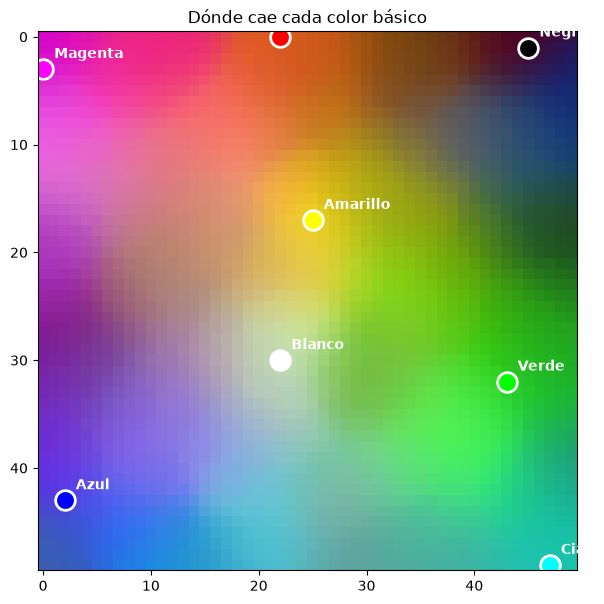

In [2]:
basicos = {"Blanco": (1,1,1), "Negro": (0,0,0), "Rojo": (1,0,0), "Verde": (0,1,0),
           "Azul": (0,0,1), "Amarillo": (1,1,0), "Magenta": (1,0,1), "Cian": (0,1,1)}

plt.figure(figsize=(7, 7))
plt.imshow(som.pesos)
for nombre, c in basicos.items():
    i, j = som.bmu(np.array(c))
    plt.scatter(j, i, s=200, c=[c], edgecolors="white", linewidths=2)
    plt.annotate(nombre, (j, i), xytext=(8, 8), textcoords="offset points",
                 color="white", fontweight="bold")
plt.title("Dónde cae cada color básico")
plt.show()

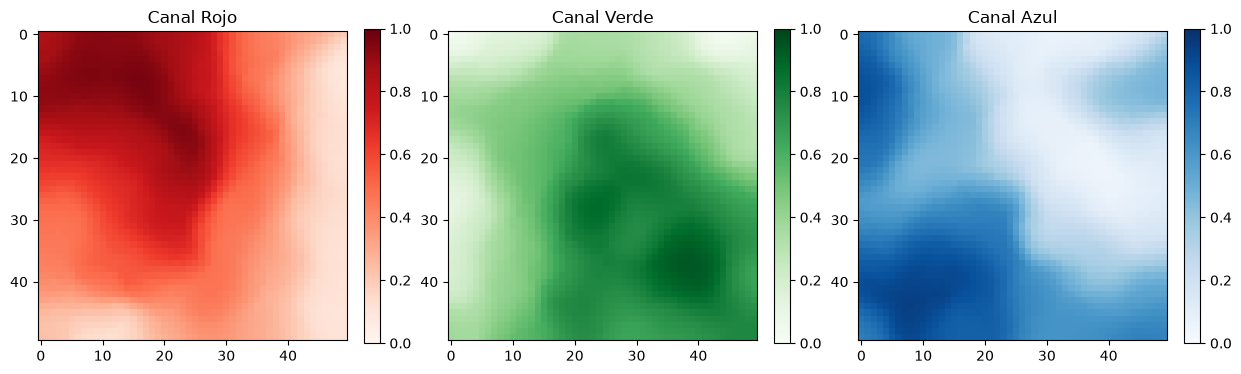

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for k, (nombre, cmap) in enumerate([("Rojo", "Reds"), ("Verde", "Greens"), ("Azul", "Blues")]):
    im = axes[k].imshow(som.pesos[:, :, k], cmap=cmap, vmin=0, vmax=1)
    axes[k].set_title(f"Canal {nombre}")
    fig.colorbar(im, ax=axes[k], fraction=0.046)
plt.show()

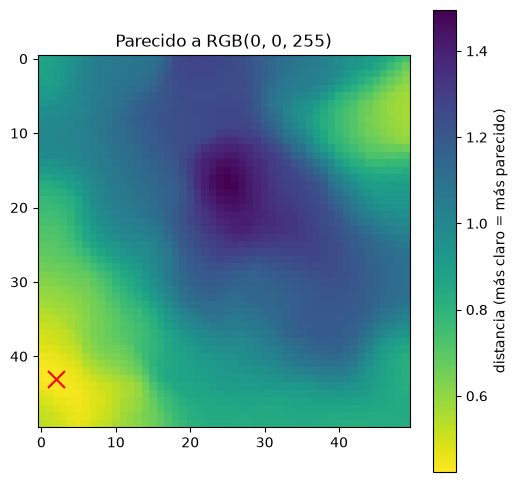

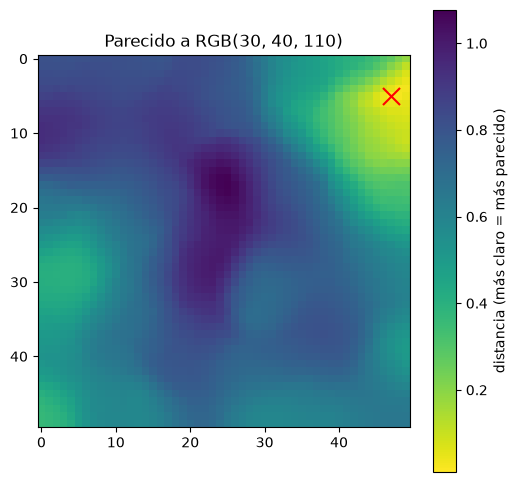

In [4]:
def mapa_parecido(rgb):
    d = np.linalg.norm(som.pesos - np.array(rgb) / 255, axis=2)
    plt.figure(figsize=(6, 6))
    plt.imshow(d, cmap="viridis_r")
    plt.colorbar(label="distancia (más claro = más parecido)")
    i, j = som.bmu(np.array(rgb) / 255)
    plt.scatter(j, i, c="red", marker="x", s=150)
    plt.title(f"Parecido a RGB{rgb}")
    plt.show()

mapa_parecido((0, 0, 255))   # azul puro
mapa_parecido((30, 40, 110)) # azul marino

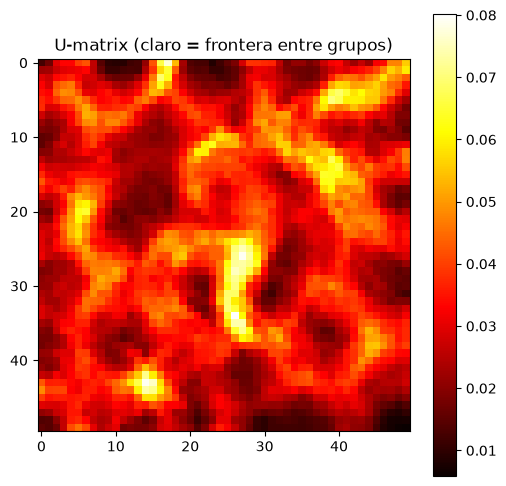

In [5]:
P = som.pesos
u = np.zeros(P.shape[:2]); n = np.zeros(P.shape[:2])
dv = np.linalg.norm(P[1:] - P[:-1], axis=2)          # vecinos de arriba/abajo
u[1:] += dv; u[:-1] += dv; n[1:] += 1; n[:-1] += 1
dh = np.linalg.norm(P[:, 1:] - P[:, :-1], axis=2)    # vecinos de izquierda/derecha
u[:, 1:] += dh; u[:, :-1] += dh; n[:, 1:] += 1; n[:, :-1] += 1
u /= n

plt.figure(figsize=(6, 6))
plt.imshow(u, cmap="hot")
plt.colorbar()
plt.title("U-matrix (claro = frontera entre grupos)")
plt.show()

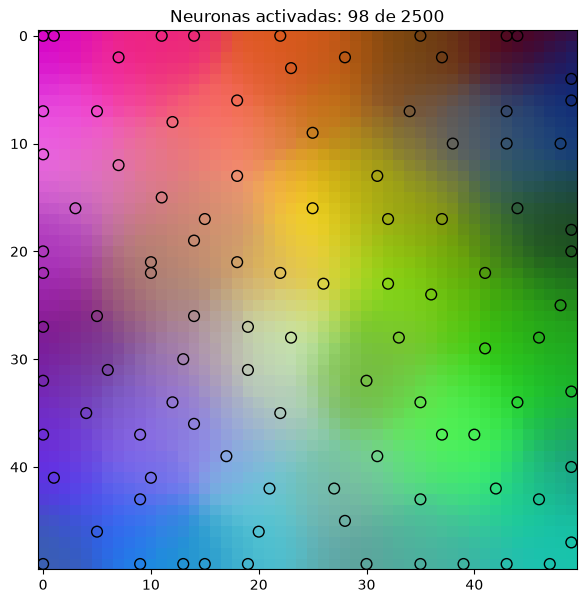

In [6]:
activ = np.zeros((som.lado, som.lado))
for x in datos:
    i, j = som.bmu(x)
    activ[i, j] += 1

plt.figure(figsize=(7, 7))
plt.imshow(som.pesos)
ii, jj = np.nonzero(activ)
plt.scatter(jj, ii, c=[som.pesos[i, j] for i, j in zip(ii, jj)],
            edgecolors="black", s=60)
plt.title(f"Neuronas activadas: {len(ii)} de {som.lado**2}")
plt.show()